In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import warnings
warnings.filterwarnings('ignore')

print("packasges loaded successfully")

packasges loaded successfully


In [2]:
xlsx_file = "orange_bike_distro_route_zones.xlsx"
 
df = pd.read_excel(xlsx_file)
 
print(f"Total accounts loaded: {len(df)}")
print(f"Columns: {list(df.columns)}")
print()

Total accounts loaded: 252
Columns: ['Account Name', 'Address', 'Corridor', 'Active 2025/26', 'Revenue Status 2026', 'Churn Risk', 'Primary Invoice Day', 'Order Frequency', 'Last Invoice Date', 'Avg Days Between Orders', '2026 Revenue', '2025 Revenue', '2024 Revenue', 'Total Historic Revenue', 'Total Invoices', 'Review Flag']



In [3]:
# Filter to accounts with 2024 revenue > 0
active = df[df['2024 Revenue'] > 0].copy()
active['2024 Revenue'] = pd.to_numeric(active['2024 Revenue'], errors='coerce')
active['Total Invoices'] = pd.to_numeric(active['Total Invoices'], errors='coerce')
active = active.dropna(subset=['2024 Revenue', 'Total Invoices'])$0

In [5]:
print(f"Accounts with 2024 revenue: {len(active)}")
print(f"2024 Revenue range: ${active['2024 Revenue'].min():,.0f} — ${active['2024 Revenue'].max():,.0f}")
print(f"Invoice count range: {active['Total Invoices'].min():.0f} — {active['Total Invoices'].max():.0f}")
print()
print("Preview:")
print(active[['Account Name', '2024 Revenue', 'Total Invoices', 'Corridor']].head(10).to_string())

Accounts with 2024 revenue: 97
2024 Revenue range: $76 — $6,617
Invoice count range: 1 — 90

Preview:
                   Account Name  2024 Revenue  Total Invoices  Corridor
0            Bow St. Forest Ave          6617              40  Portland
1           The Great Lost Bear          3675              49  Portland
2                         Apres          2234              33  Portland
3             Hilltop Superette          2318              27  Portland
4                 Another Round          1702              42  Portland
5          Bier Cellar Portland          2184              28  Portland
6               Flatbread Pizza          1757              31  Portland
7                Luke's Lobster          1834              34  Portland
8    Old Port Spirit and Cigars           498              20  Portland
9  Portland Beer Hub On Premise          1720              30  Portland


In [6]:
X = active[['2024 Revenue', 'Total Invoices']].values
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
 
print("Data normalized (StandardScaler)")
print(f"Scaled shape: {X_scaled.shape}")
print()

Data normalized (StandardScaler)
Scaled shape: (97, 2)



In [7]:
# Elbow method: inertia for k=4 to k=15
inertias = []
silhouettes = []
K_range = range(4, 16)
 
for k in K_range:
    km = KMeans(n_clusters=k, random_state=100, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))
    print(f"  k={k:2d}  inertia={km.inertia_:8.2f}  silhouette={silhouette_score(X_scaled, labels):.4f}")

  k= 4  inertia=   24.46  silhouette=0.5751
  k= 5  inertia=   16.02  silhouette=0.5620
  k= 6  inertia=   13.27  silhouette=0.5587
  k= 7  inertia=   11.56  silhouette=0.5175
  k= 8  inertia=    9.66  silhouette=0.4137
  k= 9  inertia=    8.54  silhouette=0.3758
  k=10  inertia=    6.96  silhouette=0.4041
  k=11  inertia=    6.06  silhouette=0.4036
  k=12  inertia=    5.45  silhouette=0.3898
  k=13  inertia=    4.68  silhouette=0.3869
  k=14  inertia=    4.25  silhouette=0.3810
  k=15  inertia=    3.86  silhouette=0.3722


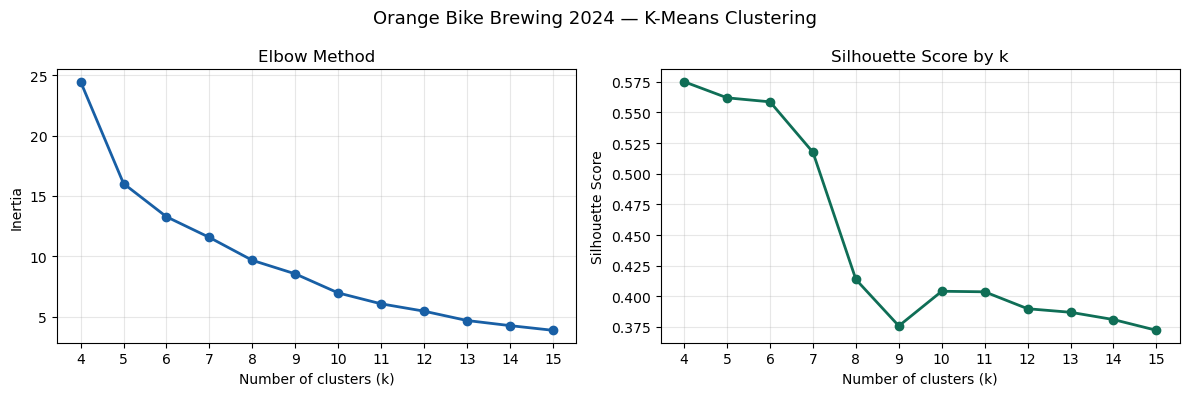

Elbow plot saved as orange_bike_kmeans_elbow.png


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
 
axes[0].plot(list(K_range), inertias, 'o-', color='#185FA5', linewidth=2, markersize=6)
axes[0].set_xlabel('Number of clusters (k)')
axes[0].set_ylabel('Inertia')
axes[0].set_title('Elbow Method')
axes[0].set_xticks(list(K_range))
axes[0].grid(True, alpha=0.3)
 
axes[1].plot(list(K_range), silhouettes, 'o-', color='#0F6E56', linewidth=2, markersize=6)
axes[1].set_xlabel('Number of clusters (k)')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_title('Silhouette Score by k')
axes[1].set_xticks(list(K_range))
axes[1].grid(True, alpha=0.3)
 
plt.suptitle('Orange Bike Brewing 2024 — K-Means Clustering', fontsize=13)
plt.tight_layout()
plt.savefig('orange_bike_kmeans_elbow_2024.png', dpi=150, bbox_inches='tight')
plt.show()
print("Elbow plot saved as orange_bike_kmeans_elbow.png")

In [9]:
K_CHOSEN = 6 
 
km_final = KMeans(n_clusters=K_CHOSEN, random_state=100, n_init=10)
active['Cluster'] = km_final.fit_predict(X_scaled)
 
# Label clusters by mean 2024 revenue (ascending) so Cluster 0 = lowest value
cluster_means = active.groupby('Cluster')['2024 Revenue'].mean().sort_values()
label_map = {old: new for new, old in enumerate(cluster_means.index)}
active['Cluster'] = active['Cluster'].map(label_map)

CLUSTER_LABELS = {
    0: 'Opportunity Group',           
    1: 'Growing Relationships', 
    2: 'Established Core',    
    3: 'High Revenue / Strong Frequency',  
    4: 'High Revenue / High Frequency',  
    5: 'Top Account(s)',     
}

active['Cluster Label'] = active['Cluster'].map(CLUSTER_LABELS)

print("Cluster label distribution:")
print(active.groupby(['Cluster','Cluster Label']).size().reset_index(name='accounts').to_string())

Cluster label distribution:
   Cluster                    Cluster Label  accounts
0        0                 Opporunity Group        49
1        1            Growing Relationships        24
2        2                 Established Core        13
3        3  High Revenue / Strong Frequency         7
4        4    High Revenue / High Frequency         3
5        5                   Top Account(s)         1


In [10]:
print(f"\nK-Means fitted with k={K_CHOSEN}")
print()
print("Cluster summary:")
summary = active.groupby('Cluster').agg(
    accounts=('Account Name', 'count'),
    avg_rev_2024=('2024 Revenue', 'mean'),
    total_rev_2024=('2024 Revenue', 'sum'),
    avg_invoices=('Total Invoices', 'mean'),
    min_rev=('2024 Revenue', 'min'),
    max_rev=('2024 Revenue', 'max'),
).round(0)
print(summary.to_string())


K-Means fitted with k=6

Cluster summary:
         accounts  avg_rev_2024  total_rev_2024  avg_invoices  min_rev  max_rev
Cluster                                                                        
0              49         396.0           19399           6.0       76     1448
1              24         941.0           22586          22.0      229     1488
2              13        2063.0           26815          34.0     1155     3204
3               7        4107.0           28751          43.0     3675     4913
4               3        5280.0           15839          79.0     4593     6153
5               1        6617.0            6617          40.0     6617     6617


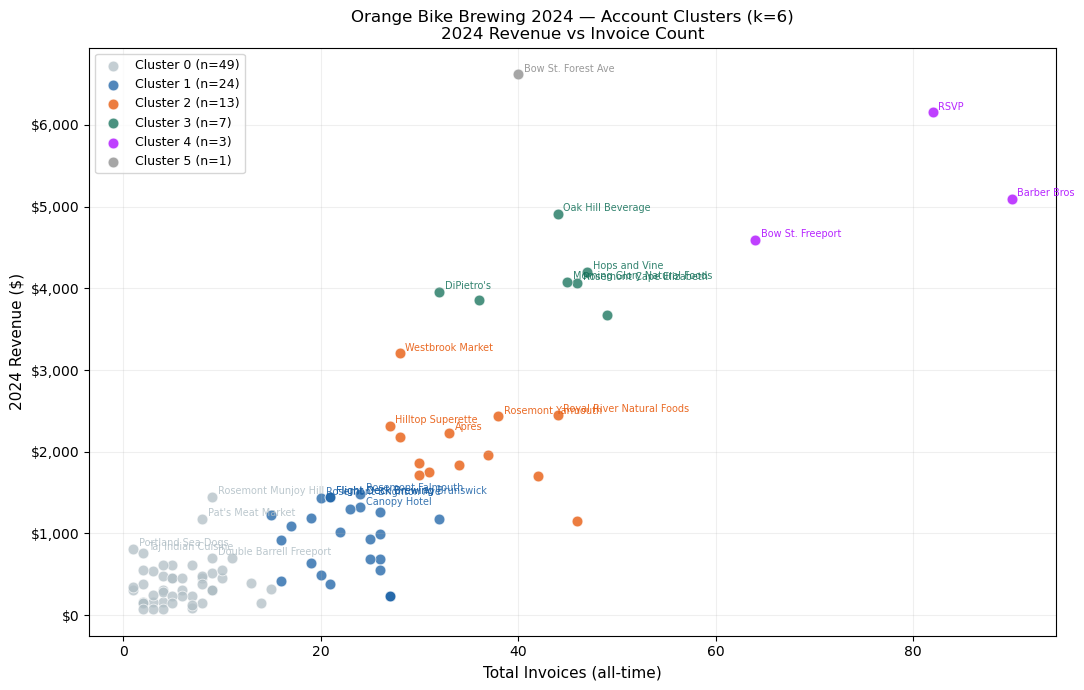

Scatter plot saved as orange_bike_kmeans_scatter.png


In [11]:
CLUSTER_COLORS = {0: '#B0BEC5', 1: '#185FA5', 2: '#E65100', 3: '#0F6E56', 4: '#AA00FF'}
 
fig, ax = plt.subplots(figsize=(11, 7))
 
for cluster_id in sorted(active['Cluster'].unique()):
    sub = active[active['Cluster'] == cluster_id]
    color = CLUSTER_COLORS.get(cluster_id, '#888')
    ax.scatter(
        sub['Total Invoices'],
        sub['2024 Revenue'],
        c=color,
        s=60,
        alpha=0.75,
        edgecolors='white',
        linewidths=0.6,
        label=f'Cluster {cluster_id} (n={len(sub)})'
    )
    # Label top 5 accounts per cluster by revenue
    for _, row in sub.nlargest(5, '2024 Revenue').iterrows():
        ax.annotate(
            row['Account Name'],
            (row['Total Invoices'], row['2024 Revenue']),
            fontsize=7,
            xytext=(4, 2),
            textcoords='offset points',
            color=color,
            alpha=0.85
        )
 
ax.set_xlabel('Total Invoices (all-time)', fontsize=11)
ax.set_ylabel('2024 Revenue ($)', fontsize=11)
ax.set_title(f'Orange Bike Brewing 2024 — Account Clusters (k={K_CHOSEN})\n2024 Revenue vs Invoice Count', fontsize=12)
ax.legend(loc='upper left', fontsize=9)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${x:,.0f}'))
ax.grid(True, alpha=0.2)
 
plt.tight_layout()
plt.savefig('orange_bike_kmeans_scatter_2024.png', dpi=150, bbox_inches='tight')
plt.show()
print("Scatter plot saved as orange_bike_kmeans_scatter.png")

In [12]:
print("\nAll accounts with cluster assignments:")
print("=" * 90)
 
for cluster_id in sorted(active['Cluster'].unique()):
    sub = active[active['Cluster'] == cluster_id].sort_values('2024 Revenue', ascending=False)
    avg_rev = sub['2024 Revenue'].mean()
    avg_inv = sub['Total Invoices'].mean()
    print(f"\nCLUSTER {cluster_id}  ({len(sub)} accounts | avg 2024 rev ${avg_rev:,.0f} | avg invoices {avg_inv:.1f})")
    print("-" * 90)
    for _, row in sub.iterrows():
        print(f"  {row['Account Name']:<50} 2024: ${row['2024 Revenue']:>7,.0f}  invoices: {int(row['Total Invoices']):<4}  corridor: {row['Corridor']}")
 


All accounts with cluster assignments:

CLUSTER 0  (49 accounts | avg 2024 rev $396 | avg invoices 5.9)
------------------------------------------------------------------------------------------
  Rosemont Munjoy Hill                               2024: $  1,448  invoices: 9     corridor: No Address
  Pat's Meat Market                                  2024: $  1,182  invoices: 8     corridor: Portland
  Portland Sea Dogs                                  2024: $    809  invoices: 1     corridor: Portland
  Taj Indian Cuisine                                 2024: $    764  invoices: 2     corridor: Cumberland South
  Double Barrell Freeport                            2024: $    706  invoices: 9     corridor: Midcoast
  Perk's Beer & Beverage                             2024: $    697  invoices: 11    corridor: Cumberland South
  Henry's Public House                               2024: $    611  invoices: 4     corridor: No Address
  Pine Tree Seafood and Produce co.                  202

In [14]:
result = df.merge(
    active[['Account Name', 'Cluster', 'Cluster Label']],
    on='Account Name',
    how='left'
)
result['Cluster'] = result['Cluster'].apply(
    lambda x: f'Cluster {int(x)}' if pd.notna(x) else 'No 2024 revenue'
)
result['Cluster Label'] = result['Cluster Label'].fillna('No 2024 revenue')

output_path = 'orange_bike_corridor_draft_with_clusters_2024.csv'
result.to_csv(output_path, index=False, encoding='utf-8-sig')
print(f"\nExported to {output_path}")
print(f"Total rows: {len(result)}")
print()
print("Cluster distribution:")
print(result['Cluster'].value_counts())


Exported to orange_bike_corridor_draft_with_clusters_2024.csv
Total rows: 252

Cluster distribution:
Cluster
No 2024 revenue    155
Cluster 0           49
Cluster 1           24
Cluster 2           13
Cluster 3            7
Cluster 4            3
Cluster 5            1
Name: count, dtype: int64
